# Data-Center Sustainability Analytics

Research question: how do resource growth and location variation affect the interpretation of infrastructure efficiency? Public-source descriptive analysis; see SOURCES.md and DATA_DICTIONARY.md.

## 1. Inspect the cleaned observations
Corporate annual values and datacenter location clusters stay separate. Missing Auckland withdrawal is censored below 1 ML, never filled with zero.

In [1]:
from pathlib import Path
import sys
root = Path.cwd().resolve()
if not (root / 'analysis.py').exists(): root = root.parent
assert (root / 'analysis.py').exists(), 'Run from project or notebooks folder'
sys.path.insert(0, str(root))
import pandas as pd
from IPython.display import display, Image
from analysis import load_clean, run, cooling_scenarios
annual, locations = load_clean()
display(annual)
display(locations.head())

,fiscal_year,electricity_mwh,water_withdrawal_ml,water_consumption_ml,water_discharge_ml,withdrawal_l_per_kwh,scope
0,2020,10770714,6794,3990,2804,0.630785,Microsoft global corporate operations; fiscal ...
1,2021,13621517,7747,4794,2953,0.568733,Microsoft global corporate operations; fiscal ...
2,2022,18153454,8698,5329,3369,0.479137,Microsoft global corporate operations; fiscal ...
3,2023,23567502,9666,5818,3848,0.410141,Microsoft global corporate operations; fiscal ...
4,2024,29829540,11590,6693,4897,0.388541,Microsoft global corporate operations; fiscal ...
5,2025,37026353,13266,8170,5096,0.358285,Microsoft global corporate operations; fiscal ...


,location,country,state,electricity_mwh,water_withdrawal_ml,water_qualifier,withdrawal_l_per_kwh,scope
0,Auckland,New Zealand,NaN,19465,NaN,lt_1_ml,NaN,Microsoft owned operated datacenter location c...
1,Busan,South Korea,NaN,196701,7.0,reported,0.035587,Microsoft owned operated datacenter location c...
2,Jakarta,Indonesia,NaN,22172,84.0,reported,3.788562,Microsoft owned operated datacenter location c...
3,Kuala Lumpur,Malaysia,NaN,19971,23.0,reported,1.151670,Microsoft owned operated datacenter location c...
4,Melbourne,Australia,NaN,12821,9.0,reported,0.701973,Microsoft owned operated datacenter location c...


In [2]:
display(annual.isna().sum().to_frame('missing'))
display(locations.isna().sum().to_frame('missing'))
assert not annual.fiscal_year.duplicated().any()
assert not locations.location.duplicated().any()
display(locations[locations.water_qualifier != 'reported'])

,missing
fiscal_year,0
electricity_mwh,0
water_withdrawal_ml,0
water_consumption_ml,0
water_discharge_ml,0
withdrawal_l_per_kwh,0
scope,0


,missing
location,0
country,0
state,18
electricity_mwh,0
water_withdrawal_ml,1
water_qualifier,0
withdrawal_l_per_kwh,1
scope,0


,location,country,state,electricity_mwh,water_withdrawal_ml,water_qualifier,withdrawal_l_per_kwh,scope
0,Auckland,New Zealand,NaN,19465,NaN,lt_1_ml,NaN,Microsoft owned operated datacenter location c...


## 2. Reproduce the analysis
Indexing to FY20=100 makes differently measured growth rates comparable. It does not make corporate and national scopes interchangeable.

In [3]:
results=run()
results

{'fy20_to_fy25_growth_percent': {'electricity_mwh': 243.7687882158973,
  'water_withdrawal_ml': 95.26052399175744,
  'water_consumption_ml': 104.76190476190474},
 'location_rows': 29,
 'censored_water_rows': 1,
 'regional_context_years': [2010, 2025],
 'ml_status': 'No model fitted: descriptive aggregate evidence only'}

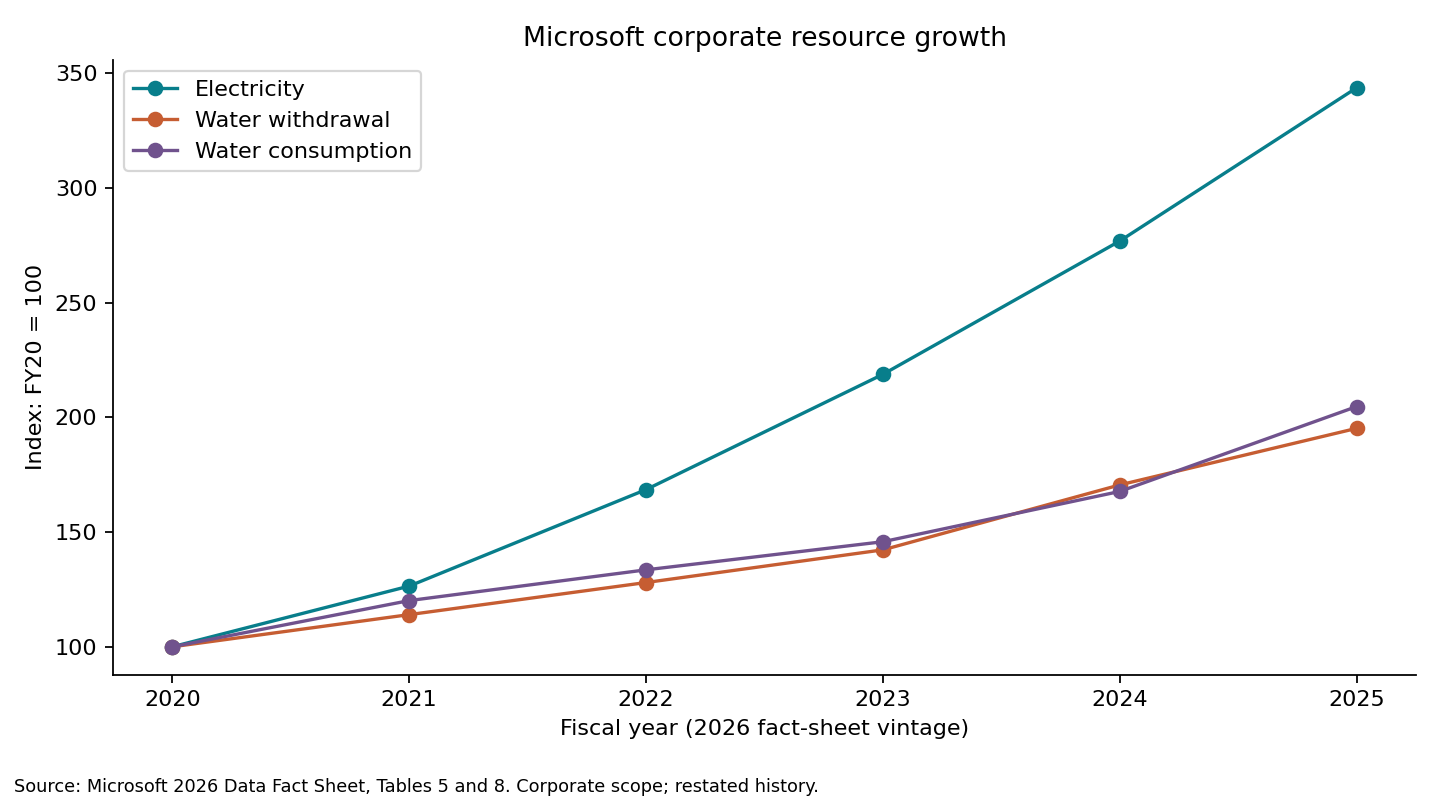

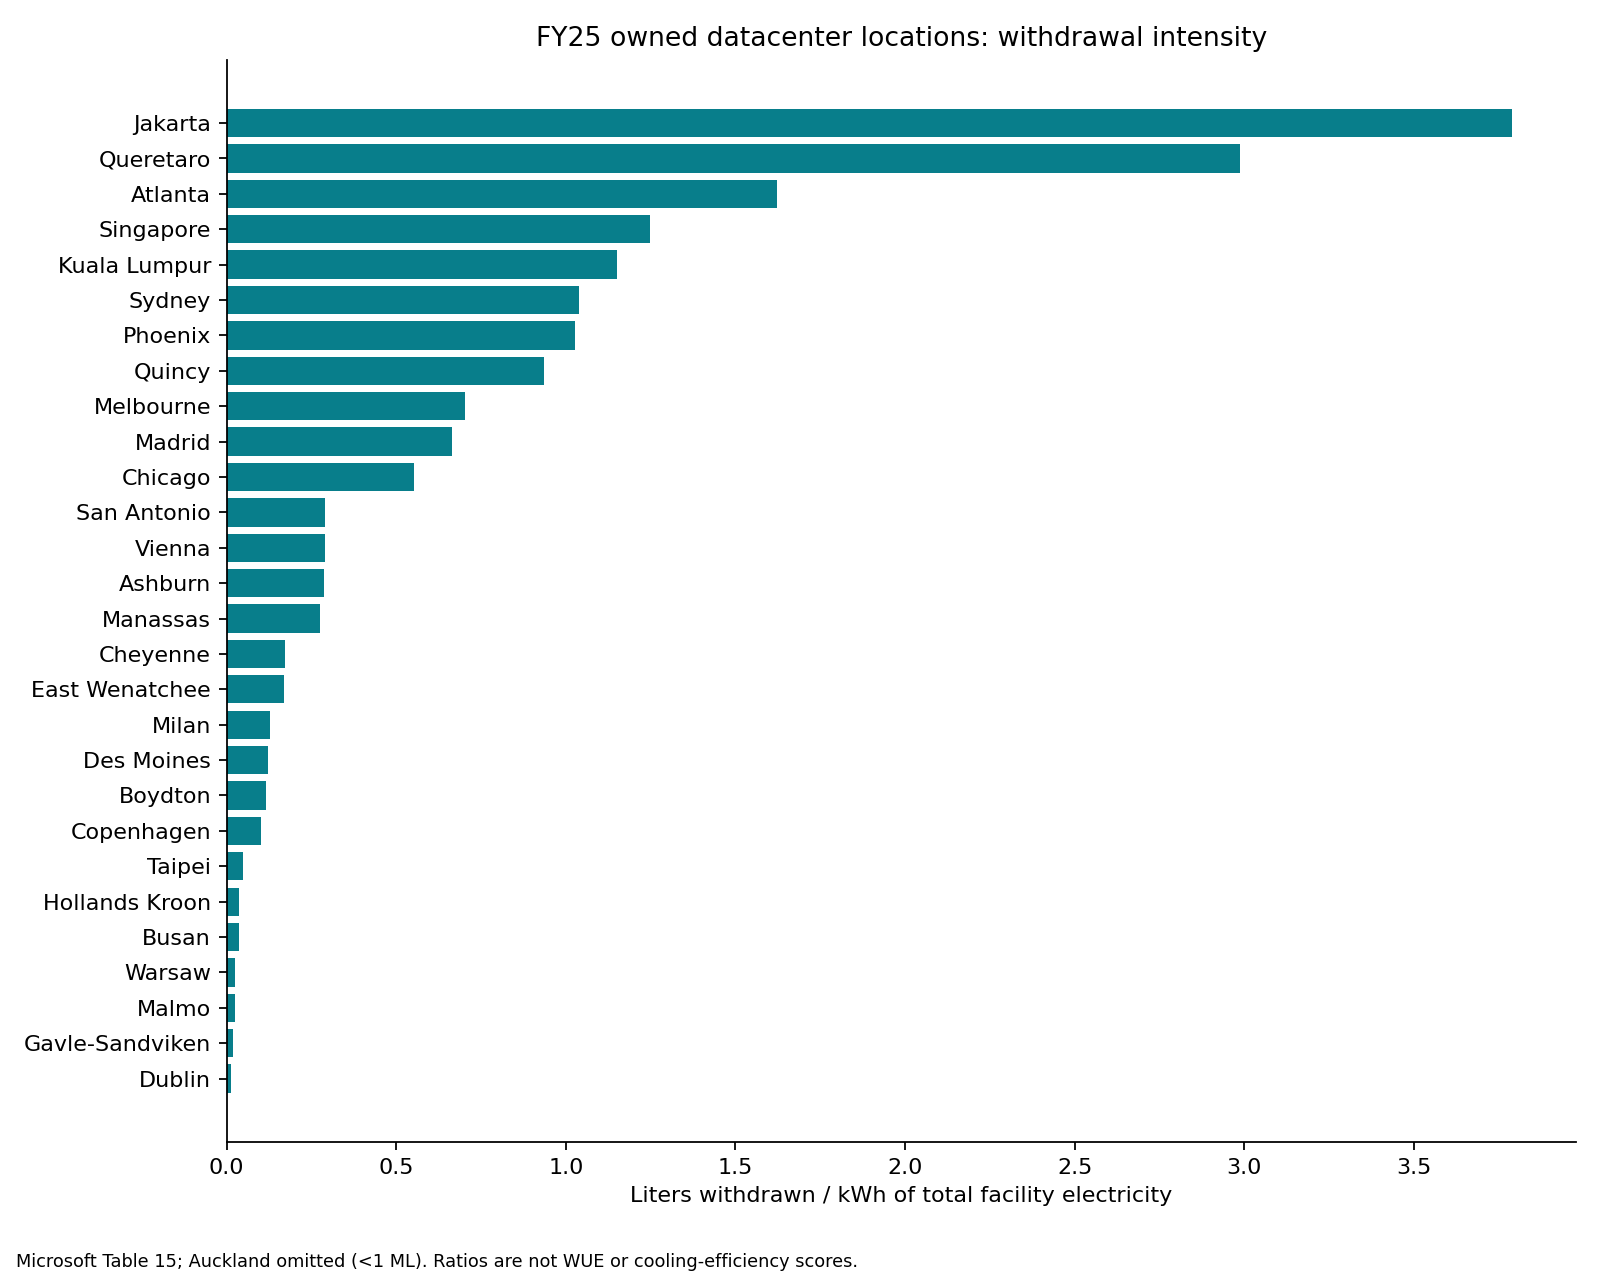

In [4]:
display(Image(filename=str(root/'reports/resource_growth.png')))
display(Image(filename=str(root/'reports/location_intensity.png')))

## 3. Test interpretation, not just arithmetic
Withdrawal intensity = ML × 1,000 / MWh, in L/kWh. It uses total facility electricity; WUE needs the relevant IT-energy denominator. Location variation may reflect climate, utilization, technology, or estimation. No causal cooling ranking follows.

,pue_assumption,it_mwh,facility_mwh,non_it_mwh
0,1.1,1000,1100.0,100.0
1,1.2,1000,1200.0,200.0
2,1.4,1000,1400.0,400.0
3,1.6,1000,1600.0,600.0


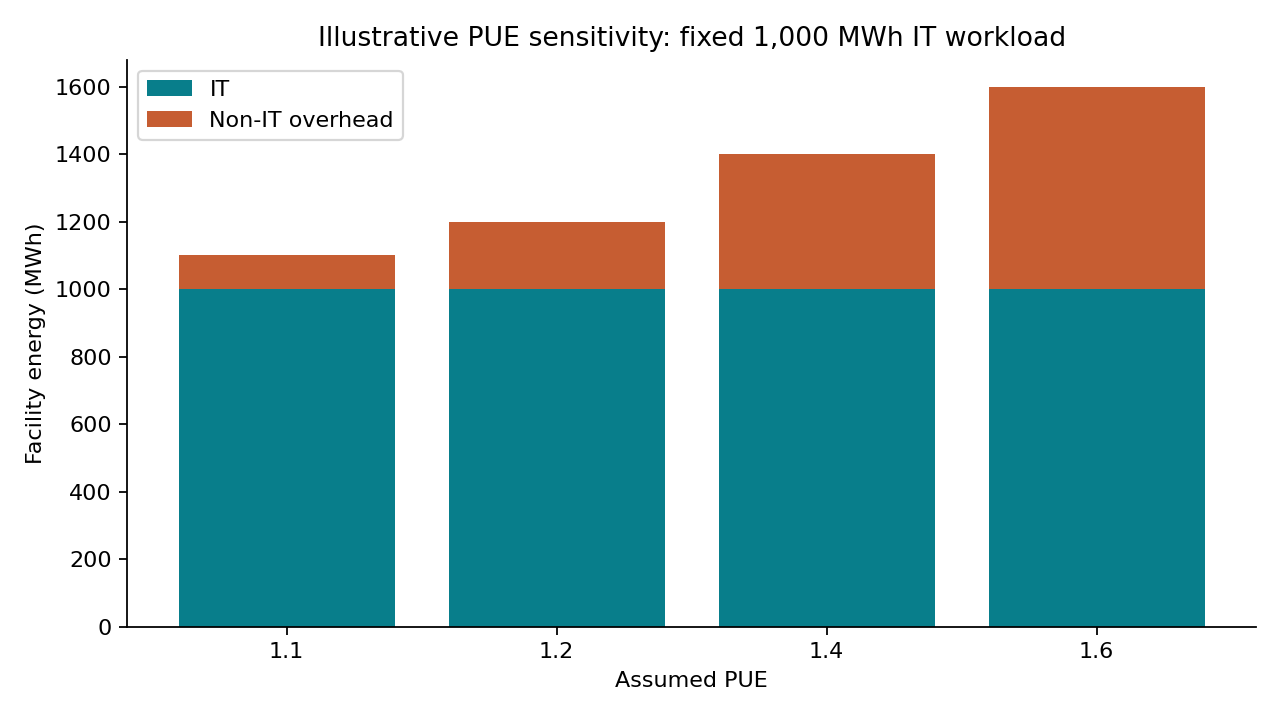

In [5]:
display(cooling_scenarios())
display(Image(filename=str(root/'reports/cooling_scenarios.png')))

## 4. Add independent context
EIA calendar-year retail sales are not datacenter-only consumption. LBNL is a modeled national estimate. No incompatible share or merged regression is calculated.

,first_year,last_year,rows
state,,,
AZ,2010,2025,16
IL,2010,2025,16
TX,2010,2025,16
VA,2010,2025,16
WA,2010,2025,16


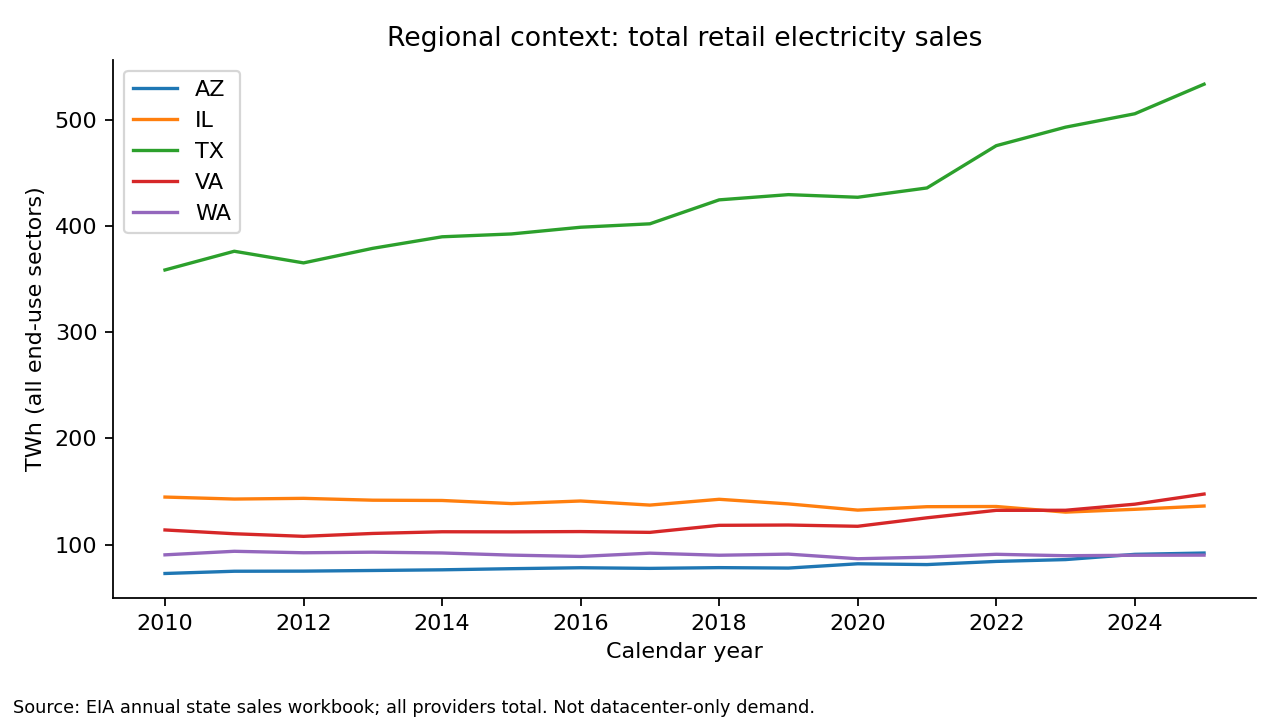

,calendar_year,metric,value,unit,scope,source_locator
0,2018,pue,1.55,ratio,US national modeled datacenter aggregate,2025 update printed page 24
1,2024,pue,1.45,ratio,US national modeled datacenter aggregate,2025 update printed page 24
2,2024,electricity,192.00,TWh,US national modeled datacenter aggregate,2025 update printed page 8


In [6]:
regional=pd.read_csv(root/'data/raw/eia_regional_sales.csv')
display(regional.groupby('state').agg(first_year=('year','min'),last_year=('year','max'),rows=('year','size')))
display(Image(filename=str(root/'reports/regional_sales.png')))
display(pd.read_csv(root/'data/raw/lbnl_context.csv'))

## 5. ML decision and next evidence
No model fitted. Six corporate observations and a one-year location cross-section do not establish predictive generalization. Seek licensed facility-month data with IT load, weather, cooling technology and measured water targets; compare a regularized model with seasonal naive prediction using future-month and location-group holdouts. Water stress and embodied hardware impacts remain research gaps.